# Fase 2: análise exploratória dos atrasos

Este notebook olha os atrasos de partida dos voos nacionais regulares (Fase 2 do projeto):
pontualidade por mês, companhia, aeroporto, hora e dia da semana, efeito dos feriados,
congestionamento e a distribuição dos atrasos. Cada gráfico termina com uma frase de conclusão.

**Base:** a mesma do modelo (tabela `features_voos`): voos nacionais (tipo `N`), regulares
(DI = `0`) e realizados, com partida prevista e real. Atraso é partida mais de 15 min depois do
previsto (ADR 002).

**Período:** de janeiro de 2022 até o mês anterior ao teste. Os 3 meses do teste ficam de fora:
eles só podem ser usados uma vez, no fim da Fase 3, e o que se vê aqui orienta escolhas do modelo.

Antes de rodar: `python -m fdr.pipeline --stage data` e `python -m fdr.pipeline --stage features`.
O notebook só lê o `data/warehouse.duckdb` (modo somente leitura) e fecha a conexão no fim.

In [23]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from fdr.config import LIMIAR_ATRASO_MIN, MESES_TESTE, WAREHOUSE

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

AZUL = "#2a78d6"
TEXTO = "#0b0b0b"
TEXTO_SECUNDARIO = "#52514e"
GRADE = "#e4e3df"
FUNDO = "#fcfcfb"
FONTE = "Fonte: ANAC, Voo Regular Ativo (VRA). Voos nacionais regulares realizados."

plt.rcParams.update(
    {
        "figure.facecolor": FUNDO,
        "axes.facecolor": FUNDO,
        "axes.edgecolor": GRADE,
        "axes.labelcolor": TEXTO_SECUNDARIO,
        "xtick.color": TEXTO_SECUNDARIO,
        "ytick.color": TEXTO_SECUNDARIO,
        "font.size": 9,
    }
)

con = duckdb.connect(str(WAREHOUSE), read_only=True)


def consulta(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


def estilo(eixo, titulo: str, grade: str = "y") -> None:
    """Visual comum: título à esquerda, só a grade do eixo dos valores, sem bordas."""
    eixo.set_title(titulo, loc="left", fontsize=11, color=TEXTO, pad=8)
    eixo.grid(axis=grade, color=GRADE, lw=0.8)
    eixo.set_axisbelow(True)
    for lado in ("top", "right", "left", "bottom"):
        eixo.spines[lado].set_visible(False)
    eixo.tick_params(length=0)


def rodape(figura, texto: str = FONTE) -> None:
    figura.text(0.01, 0.005, texto, fontsize=8, color=TEXTO_SECUNDARIO)
    figura.tight_layout(rect=(0, 0.03, 1, 1))


def com_intervalo(tabela: pd.DataFrame) -> pd.DataFrame:
    """Taxa de atraso com intervalo de Wilson de 95% (grupos pequenos têm intervalo largo)."""
    n = tabela["voos"].astype(float)
    p = tabela["atrasados"] / n
    z = 1.96
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    meia = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return tabela.assign(taxa=p, ic_inf=centro - meia, ic_sup=centro + meia)


def taxa_por(expressao: str, nome: str, tabela: str = "eda") -> pd.DataFrame:
    tabela_grupos = consulta(f"""
        select {expressao} as {nome}, count(*) as voos, sum(atrasado_15) as atrasados
        from {tabela}
        group by 1
        order by 1
    """)
    return com_intervalo(tabela_grupos)

## 1. Base da análise

In [24]:
meses = [m for (m,) in con.sql("select distinct mes from features_voos order by 1").fetchall()]
inicio_teste = meses[-MESES_TESTE]
con.execute(f"""
    create or replace temp view eda as
    select f.*, v.atraso_partida_min
    from features_voos f
    join fct_flights v using (voo_id)
    where f.mes < date '{inicio_teste}'
""")
resumo = con.sql("""
    select min(mes) as primeiro_mes, max(mes) as ultimo_mes, count(*) as voos,
           avg(atrasado_15) as taxa_atraso
    from eda
""").df()
TAXA_GERAL = float(resumo.loc[0, "taxa_atraso"])
print(f"Teste (fora desta análise): a partir de {inicio_teste:%m/%Y}.")
resumo

Teste (fora desta análise): a partir de 06/2026.


,primeiro_mes,ultimo_mes,voos,taxa_atraso
0,2022-01-01,2026-05-01,3282095,0.148943


## 2. Pontualidade por mês

Em cima, a série mês a mês. Embaixo, a taxa por mês do ano, somando todos os anos do período.

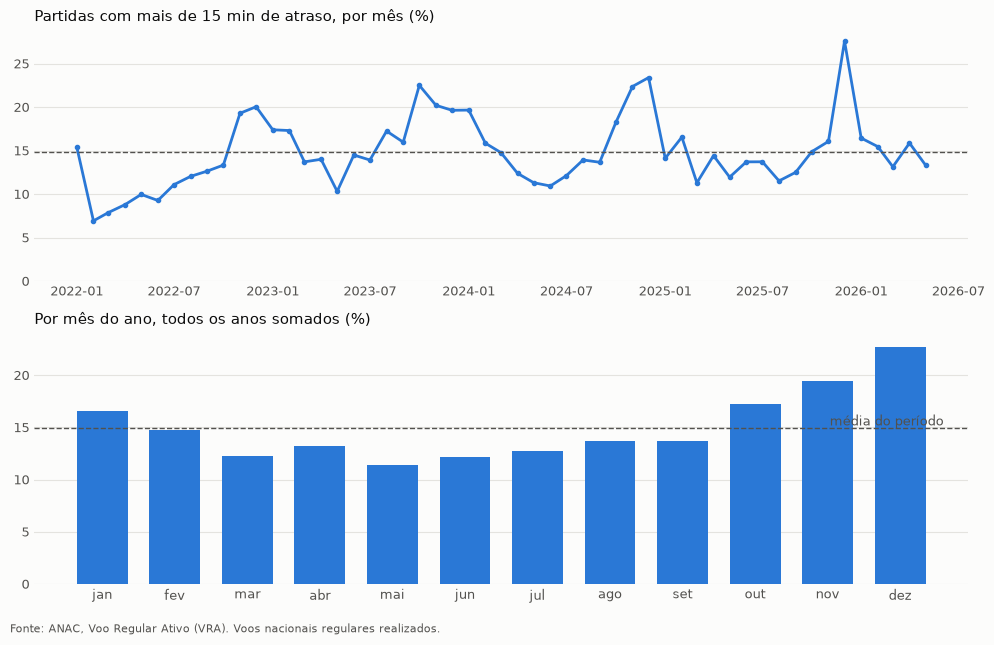

,mes_do_ano,voos,atrasados,taxa,ic_inf,ic_sup,mes
0,1,324831,53907.0,0.1660,0.1647,0.1672,jan
1,2,277456,40820.0,0.1471,0.1458,0.1484,fev
2,3,308314,37841.0,0.1227,0.1216,0.1239,mar
3,4,298947,39512.0,0.1322,0.1310,0.1334,abr
4,5,310924,35417.0,0.1139,0.1128,0.1150,mai
5,6,238996,29140.0,0.1219,0.1206,0.1232,jun
6,7,264563,33673.0,0.1273,0.1260,0.1286,jul
7,8,256797,35221.0,0.1372,0.1358,0.1385,ago
8,9,246979,33825.0,0.1370,0.1356,0.1383,set
9,10,253442,43609.0,0.1721,0.1706,0.1735,out


In [25]:
mensal = taxa_por("mes", "mes")
mes_do_ano = taxa_por("month(mes)", "mes_do_ano")
NOMES_MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

figura, (serie, sazonal) = plt.subplots(2, 1, figsize=(10, 6.4))
serie.plot(mensal["mes"], mensal["taxa"] * 100, color=AZUL, lw=2, marker="o", ms=3)
serie.axhline(TAXA_GERAL * 100, color=TEXTO_SECUNDARIO, lw=1, ls="--")
serie.set_ylim(bottom=0)
estilo(serie, "Partidas com mais de 15 min de atraso, por mês (%)")

sazonal.bar(mes_do_ano["mes_do_ano"], mes_do_ano["taxa"] * 100, color=AZUL, width=0.7)
sazonal.axhline(TAXA_GERAL * 100, color=TEXTO_SECUNDARIO, lw=1, ls="--")
sazonal.set_xticks(range(1, 13), NOMES_MESES)
estilo(sazonal, "Por mês do ano, todos os anos somados (%)")
sazonal.text(12.6, TAXA_GERAL * 100, "média do período", va="bottom", ha="right",
             color=TEXTO_SECUNDARIO)  # fmt: skip
rodape(figura)
plt.show()
mes_do_ano.assign(mes=[NOMES_MESES[m - 1] for m in mes_do_ano["mes_do_ano"]]).round(4)

> **Conclusão:** A pontualidade tem sazonalidade forte: a taxa de atraso vai de 11,4% em maio a 22,7% em
> dezembro, os meses de outubro a janeiro ficam acima da média do período (14,9%) e cada fim de ano
> traz um pico, o maior em dezembro de 2025.

## 3. Pontualidade por companhia

Companhias com pelo menos 1% dos voos do período. As barras finas são o intervalo de 95%.

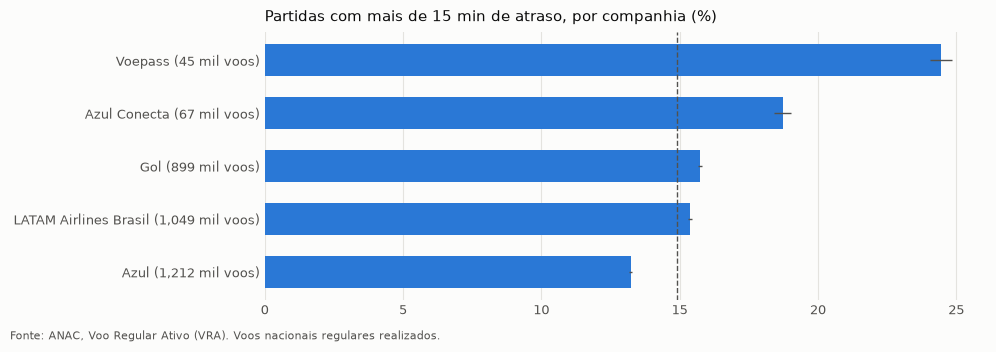

,cia,nome,voos,taxa,ic_inf,ic_sup
1,AZU,Azul,1211866,0.1323,0.1317,0.1329
4,TAM,LATAM Airlines Brasil,1049420,0.1538,0.1531,0.1545
2,GLO,Gol,899197,0.1573,0.1566,0.1581
0,ACN,Azul Conecta,66772,0.1872,0.1842,0.1902
3,PTB,Voepass,44721,0.2445,0.2405,0.2485


In [26]:
por_cia = taxa_por("cia", "cia")
por_cia = por_cia[por_cia["voos"] >= 0.01 * por_cia["voos"].sum()]
nomes_cia = consulta("select cia, nome from dim_airlines")
por_cia = por_cia.merge(nomes_cia, on="cia", how="left").sort_values("taxa")
rotulos = [
    f"{n} ({v / 1000:,.0f} mil voos)" for n, v in zip(por_cia["nome"], por_cia["voos"], strict=True)
]

figura, eixo = plt.subplots(figsize=(10, 0.45 * len(por_cia) + 1.2))
erro = [(por_cia["taxa"] - por_cia["ic_inf"]) * 100, (por_cia["ic_sup"] - por_cia["taxa"]) * 100]
eixo.barh(rotulos, por_cia["taxa"] * 100, color=AZUL, height=0.6, xerr=erro,
          error_kw={"ecolor": TEXTO_SECUNDARIO, "lw": 1})  # fmt: skip
eixo.axvline(TAXA_GERAL * 100, color=TEXTO_SECUNDARIO, lw=1, ls="--")
estilo(eixo, "Partidas com mais de 15 min de atraso, por companhia (%)", grade="x")
rodape(figura)
plt.show()
por_cia[["cia", "nome", "voos", "taxa", "ic_inf", "ic_sup"]].round(4)

> **Conclusão:** Entre as 5 companhias com pelo menos 1% dos voos, a Azul é a mais pontual (13,2%), LATAM
> (15,4%) e Gol (15,7%) ficam perto da média, e as regionais Azul Conecta (18,7%) e Voepass (24,5%)
> atrasam mais; com dezenas a centenas de milhares de voos por companhia, os intervalos são estreitos
> e as diferenças não são obra do acaso.

## 4. Pontualidade por aeroporto de origem

Os 20 aeroportos com mais partidas no período.

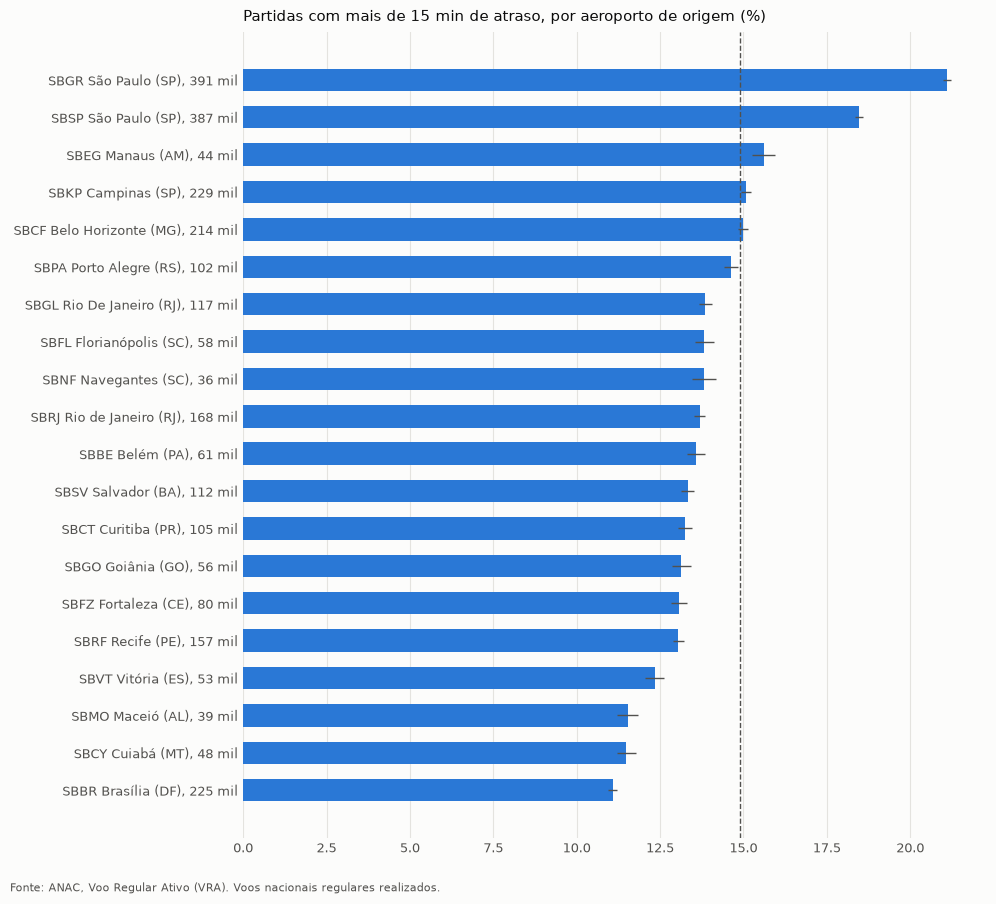

,origem,cidade,uf,voos,taxa
3,SBBR,Brasília,DF,224640,0.1108
16,SBCY,Cuiabá,MT,47843,0.1148
18,SBMO,Maceió,AL,39263,0.1153
15,SBVT,Vitória,ES,53399,0.1233
6,SBRF,Recife,PE,156792,0.1305
11,SBFZ,Fortaleza,CE,79579,0.1307
14,SBGO,Goiânia,GO,56485,0.1313
9,SBCT,Curitiba,PR,105243,0.1324
8,SBSV,Salvador,BA,112360,0.1333
12,SBBE,Belém,PA,60981,0.1356


In [27]:
por_origem = taxa_por("origem", "origem").nlargest(20, "voos")
nomes_aeroporto = consulta("select icao as origem, cidade, uf from dim_airports")
por_origem = por_origem.merge(nomes_aeroporto, on="origem", how="left").sort_values("taxa")
rotulos = [
    f"{o} {c} ({u}), {v / 1000:,.0f} mil"
    for o, c, u, v in zip(
        por_origem["origem"],
        por_origem["cidade"],
        por_origem["uf"],
        por_origem["voos"],
        strict=True,
    )
]

figura, eixo = plt.subplots(figsize=(10, 9))
erro = [
    (por_origem["taxa"] - por_origem["ic_inf"]) * 100,
    (por_origem["ic_sup"] - por_origem["taxa"]) * 100,
]
eixo.barh(rotulos, por_origem["taxa"] * 100, color=AZUL, height=0.6, xerr=erro,
          error_kw={"ecolor": TEXTO_SECUNDARIO, "lw": 1})  # fmt: skip
eixo.axvline(TAXA_GERAL * 100, color=TEXTO_SECUNDARIO, lw=1, ls="--")
estilo(eixo, "Partidas com mais de 15 min de atraso, por aeroporto de origem (%)", grade="x")
rodape(figura)
plt.show()
por_origem[["origem", "cidade", "uf", "voos", "taxa"]].round(4)

> **Conclusão:** Os dois aeroportos de São Paulo se destacam, com Guarulhos (21,1%) e Congonhas (18,5%) bem
> acima da média, enquanto Brasília, o 4º em volume (225 mil partidas), tem a menor taxa entre os 20
> (11,1%): o aeroporto de origem pesa no atraso, e não só pelo tamanho.

## 5. Pontualidade por hora da partida

Hora prevista no horário local do aeroporto de origem. A faixa clara é o intervalo de 95%; nas
horas com poucos voos (madrugada) ela fica mais larga.

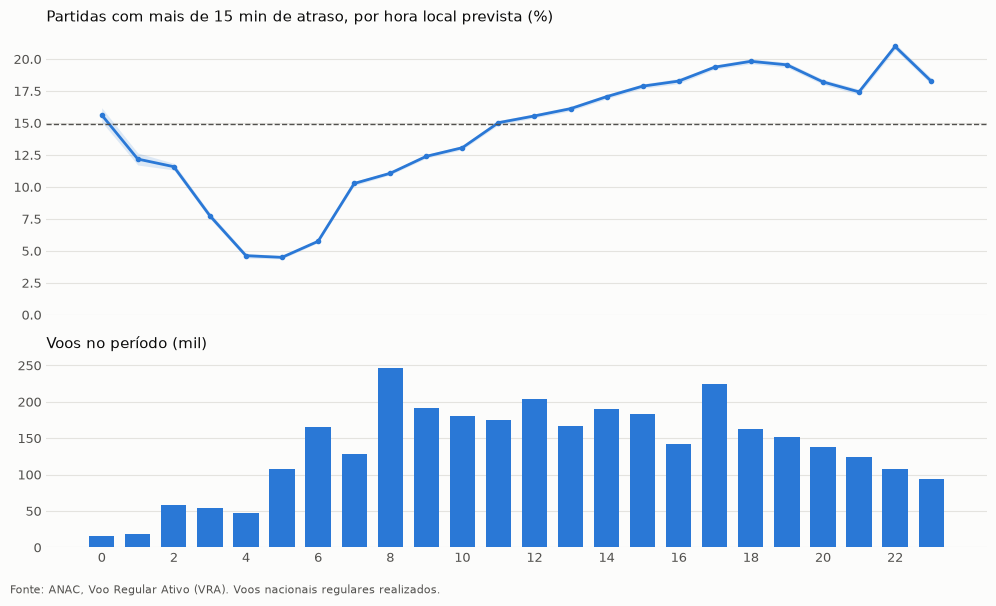

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
hora,0.0000,1.0000,2.0000,3.0000,4.0000,5.000,6.0000,7.0000,8.0000,9.000,...,14.0000,15.0000,16.0000,17.0000,18.0000,19.0000,20.0000,21.0000,22.0000,23.0000
voos,16366.0000,18514.0000,57671.0000,54629.0000,47951.0000,107984.000,165594.0000,127766.0000,246243.0000,192102.000,...,190338.0000,183612.0000,142137.0000,225106.0000,162561.0000,152083.0000,138587.0000,124322.0000,108187.0000,93638.0000
taxa,0.1564,0.1219,0.1159,0.0775,0.0463,0.045,0.0576,0.1028,0.1107,0.124,...,0.1707,0.1789,0.1829,0.1938,0.1983,0.1956,0.1822,0.1744,0.2099,0.1828


In [28]:
por_hora = taxa_por("hora_prevista_local", "hora")

figura, (taxa, volume) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)
taxa.fill_between(por_hora["hora"], por_hora["ic_inf"] * 100, por_hora["ic_sup"] * 100,
                  color=AZUL, alpha=0.15, lw=0)  # fmt: skip
taxa.plot(por_hora["hora"], por_hora["taxa"] * 100, color=AZUL, lw=2, marker="o", ms=3)
taxa.axhline(TAXA_GERAL * 100, color=TEXTO_SECUNDARIO, lw=1, ls="--")
taxa.set_ylim(bottom=0)
estilo(taxa, "Partidas com mais de 15 min de atraso, por hora local prevista (%)")
volume.bar(por_hora["hora"], por_hora["voos"] / 1000, color=AZUL, width=0.7)
volume.set_xticks(range(0, 24, 2))
estilo(volume, "Voos no período (mil)")
rodape(figura)
plt.show()
por_hora[["hora", "voos", "taxa"]].round(4).T

> **Conclusão:** O atraso se acumula ao longo do dia: é mínimo nas primeiras partidas da manhã (4,5% às 5h),
> passa de 17% a partir das 14h e chega a 21,0% às 22h, padrão compatível com a propagação do atraso
> de um voo para os seguintes.

## 6. Pontualidade por dia da semana

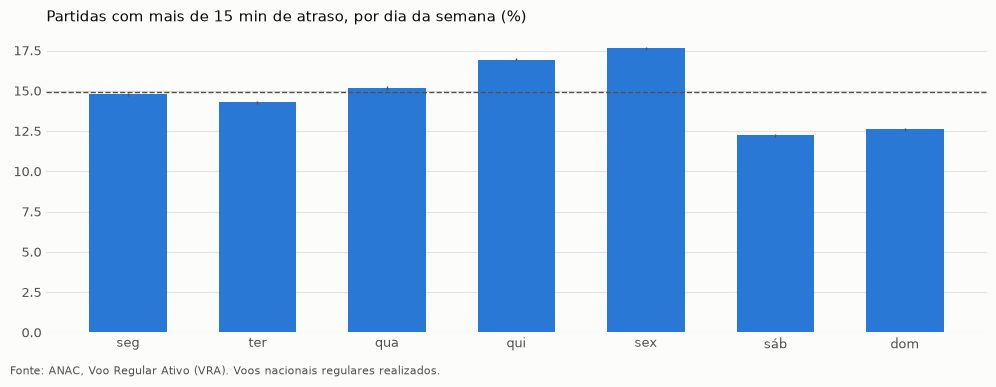

,dia,voos,taxa
0,seg,492298,0.1478
1,ter,482562,0.1429
2,qua,482390,0.1518
3,qui,483250,0.1693
4,sex,487998,0.1763
5,sáb,406485,0.1223
6,dom,447112,0.1261


In [29]:
por_dia = taxa_por("dia_semana", "dia_semana")
DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]

figura, eixo = plt.subplots(figsize=(10, 3.8))
erro = [(por_dia["taxa"] - por_dia["ic_inf"]) * 100, (por_dia["ic_sup"] - por_dia["taxa"]) * 100]
eixo.bar(DIAS, por_dia["taxa"] * 100, color=AZUL, width=0.6, yerr=erro,
         error_kw={"ecolor": TEXTO_SECUNDARIO, "lw": 1})  # fmt: skip
eixo.axhline(TAXA_GERAL * 100, color=TEXTO_SECUNDARIO, lw=1, ls="--")
estilo(eixo, "Partidas com mais de 15 min de atraso, por dia da semana (%)")
rodape(figura)
plt.show()
por_dia.assign(dia=DIAS)[["dia", "voos", "taxa"]].round(4)

> **Conclusão:** Quinta (16,9%) e sexta (17,6%) são os dias com mais atraso, e sábado (12,2%) e domingo (12,6%)
> os com menos, que também são os dias com menos voos (406 mil e 447 mil, contra 482 mil a 492 mil
> nos dias úteis).

## 7. Efeito dos feriados

Feriados nacionais (biblioteca `holidays`), a véspera e o dia seguinte. Como os feriados se
concentram em alguns meses (dezembro tem a maior taxa do ano), comparar só as taxas mistura o
efeito do feriado com o do mês. Por isso o painel da direita compara cada voo com os **dias comuns
do mesmo mês**: é a diferença entre a taxa observada e a que se esperaria num dia comum daquele mês.

As férias escolares ficam de fora do gráfico: na base, elas são definidas pelo mês (janeiro, julho
e a segunda quinzena de dezembro), então o efeito delas já aparece na seção 2.

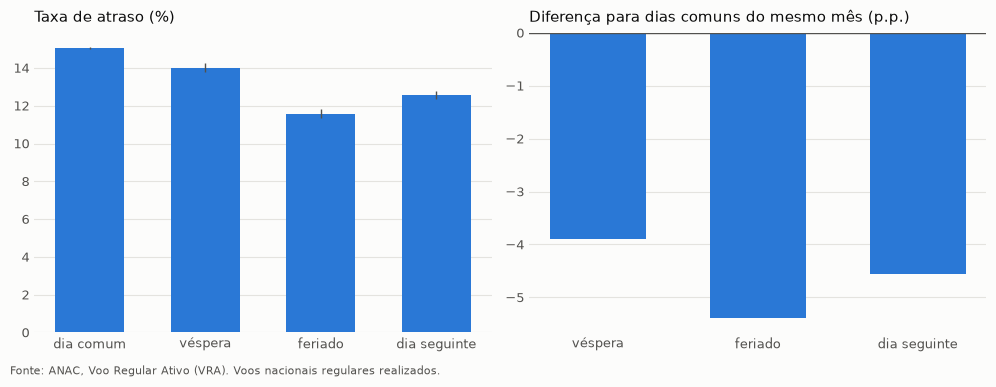

,categoria,voos,taxa,esperado,diferenca_pp
0,dia comum,3047908,0.1506,0.1506,-0.0000
1,véspera,78432,0.1400,0.1789,-3.8895
2,feriado,75908,0.1157,0.1697,-5.3930
3,dia seguinte,79847,0.1257,0.1714,-4.5631


,ferias_escolares,voos,taxa
0,0,2551172,0.1458
1,1,730923,0.1599


In [30]:
CATEGORIA = """
    case
        when feriado = 1 then '2. feriado'
        when vespera_feriado = 1 then '1. véspera'
        when pos_feriado = 1 then '3. dia seguinte'
        else '0. dia comum'
    end
"""
feriados = consulta(f"""
    with base as (
        select mes, atrasado_15, {CATEGORIA} as categoria from eda
    ),
    comum as (
        select mes, avg(atrasado_15) as taxa_comum
        from base where categoria = '0. dia comum' group by mes
    )
    select categoria, count(*) as voos, sum(atrasado_15) as atrasados,
           avg(taxa_comum) as esperado
    from base join comum using (mes)
    group by categoria
    order by categoria
""")
feriados = com_intervalo(feriados)
feriados["diferenca_pp"] = (feriados["taxa"] - feriados["esperado"]) * 100
feriados["categoria"] = feriados["categoria"].str[3:]

figura, (bruta, ajustada) = plt.subplots(1, 2, figsize=(10, 3.8))
erro = [
    (feriados["taxa"] - feriados["ic_inf"]) * 100,
    (feriados["ic_sup"] - feriados["taxa"]) * 100,
]
bruta.bar(feriados["categoria"], feriados["taxa"] * 100, color=AZUL, width=0.6, yerr=erro,
          error_kw={"ecolor": TEXTO_SECUNDARIO, "lw": 1})  # fmt: skip
estilo(bruta, "Taxa de atraso (%)")
outros = feriados[feriados["categoria"] != "dia comum"]
ajustada.bar(outros["categoria"], outros["diferenca_pp"], color=AZUL, width=0.6)
ajustada.axhline(0, color=TEXTO_SECUNDARIO, lw=1)
estilo(ajustada, "Diferença para dias comuns do mesmo mês (p.p.)")
rodape(figura)
plt.show()

ferias = taxa_por("ferias_escolares", "ferias_escolares")
display(feriados[["categoria", "voos", "taxa", "esperado", "diferenca_pp"]].round(4))
ferias[["ferias_escolares", "voos", "taxa"]].round(4)

> **Conclusão:** Feriados não pioram a pontualidade: comparados com os dias comuns do mesmo mês, a véspera tem
> 3,9 p.p. a menos de atraso, o feriado 5,4 p.p. a menos e o dia seguinte 4,6 p.p. a menos; já a
> diferença das férias escolares (16,0% contra 14,6% fora delas) repete o efeito de dezembro e
> janeiro visto na seção 2.

## 8. Congestionamento e atraso

Congestionamento programado: quantas partidas regulares a origem tinha previstas naquela data e
hora (variável `partidas_programadas_origem_hora`, conhecida antes do voo). Em cima, todos os
aeroportos juntos. Embaixo, os 4 aeroportos com mais voos, cada um com a própria escala: assim a
comparação fica dentro do mesmo aeroporto, e não entre aeroportos grandes e pequenos.

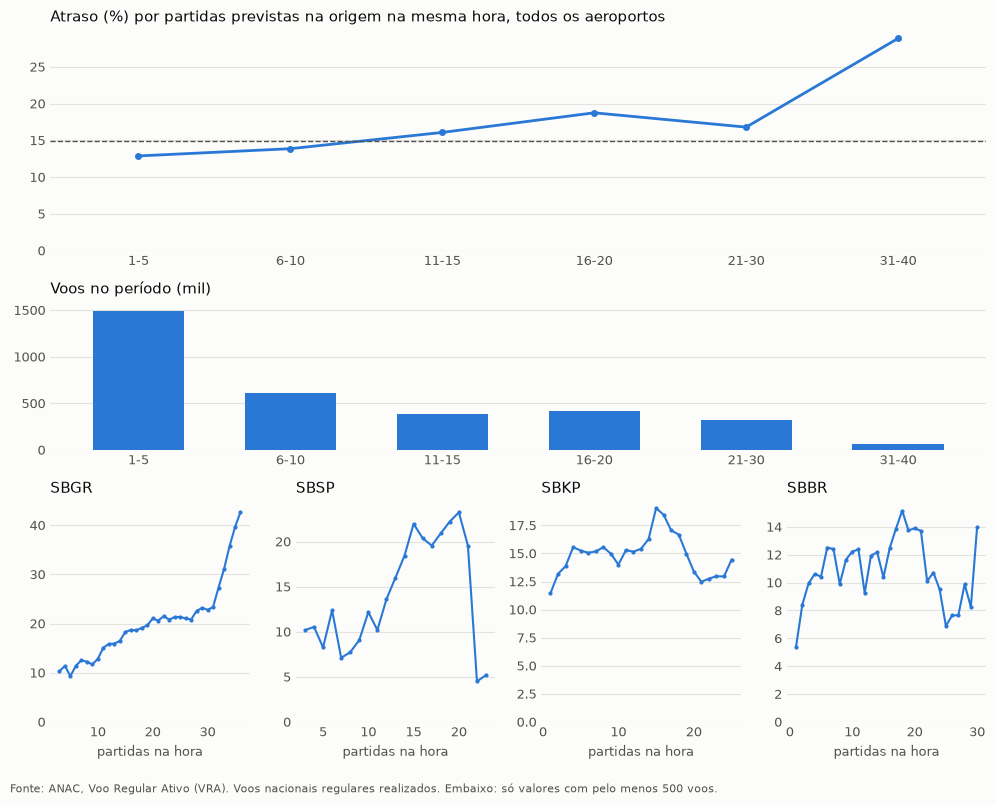

,faixa,voos,taxa
0,1-5,1485924,0.1288
5,6-10,606813,0.1387
1,11-15,382247,0.1608
2,16-20,416428,0.1875
3,21-30,323058,0.1680
4,31-40,67625,0.2887


In [31]:
FAIXAS = [0, 5, 10, 15, 20, 30, 40, 1000]
NOMES_FAIXAS = ["1-5", "6-10", "11-15", "16-20", "21-30", "31-40", "41+"]


def faixa(coluna: str) -> str:
    casos = " ".join(
        f"when {coluna} <= {fim} then '{nome}'"
        for fim, nome in zip(FAIXAS[1:], NOMES_FAIXAS, strict=True)
    )
    return f"case {casos} end"


congestao = taxa_por(faixa("partidas_programadas_origem_hora"), "faixa")
congestao["ordem"] = congestao["faixa"].map(NOMES_FAIXAS.index)
congestao = congestao.sort_values("ordem")

maiores = consulta("select origem from eda group by 1 order by count(*) desc limit 4")["origem"]
lista = ", ".join(f"'{o}'" for o in maiores)
por_aeroporto = com_intervalo(
    consulta(f"""
        select origem, partidas_programadas_origem_hora as partidas,
               count(*) as voos, sum(atrasado_15) as atrasados
        from eda
        where origem in ({lista})
        group by all
        having count(*) >= 500
        order by origem, partidas
    """)
)

figura = plt.figure(figsize=(10, 8))
grade = figura.add_gridspec(3, 4, height_ratios=[3, 2, 3])
taxa = figura.add_subplot(grade[0, :])
volume = figura.add_subplot(grade[1, :], sharex=taxa)
taxa.plot(congestao["faixa"], congestao["taxa"] * 100, color=AZUL, lw=2, marker="o", ms=4)
taxa.axhline(TAXA_GERAL * 100, color=TEXTO_SECUNDARIO, lw=1, ls="--")
taxa.set_ylim(bottom=0)
estilo(taxa, "Atraso (%) por partidas previstas na origem na mesma hora, todos os aeroportos")
volume.bar(congestao["faixa"], congestao["voos"] / 1000, color=AZUL, width=0.6)
estilo(volume, "Voos no período (mil)")
for i, origem in enumerate(maiores):
    eixo = figura.add_subplot(grade[2, i])
    dados = por_aeroporto[por_aeroporto["origem"] == origem]
    eixo.plot(dados["partidas"], dados["taxa"] * 100, color=AZUL, lw=1.5, marker="o", ms=2)
    eixo.set_ylim(bottom=0)
    eixo.set_xlabel("partidas na hora")
    estilo(eixo, origem)
rodape(figura, FONTE + " Embaixo: só valores com pelo menos 500 voos.")
plt.show()
congestao[["faixa", "voos", "taxa"]].round(4)

> **Conclusão:** Mais partidas previstas na mesma hora vêm com mais atraso, de 12,9% (1 a 5 partidas) para
> 18,8% (16 a 20) e 28,9% (31 a 40), mas a relação não é linear: em Guarulhos a taxa sobe de cerca de
> 10% para mais de 40% dentro do próprio aeroporto, enquanto em Congonhas, Campinas e Brasília a curva
> sobe e depois cai, então o efeito depende do aeroporto e se mistura com o da hora do dia.

## 9. Distribuição dos atrasos

Atraso de partida em minutos (partida real menos prevista); valores negativos são partidas
adiantadas. À esquerda, o histograma de −30 a 180 min, em faixas de 5 min, com a linha do limiar de
15 min. À direita, a fração de voos com atraso acima de cada valor, em escala logarítmica, para
ver a cauda longa.

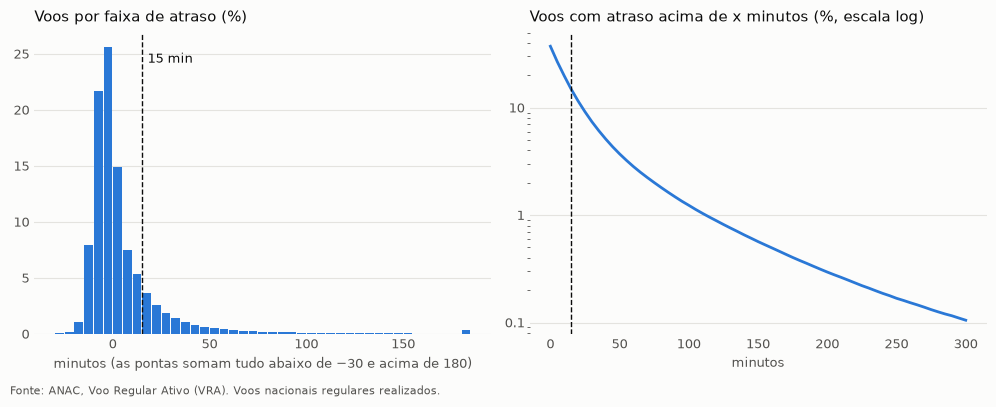

,0
adiantados,0.5656
acima_15,0.1489
acima_30,0.074
acima_60,0.0283
acima_120,0.0089
percentis_10_25_50_75_90_95_99,"[-10.0, -7.0, -2.0, 7.0, 24.0, 41.0, 113.0]"


In [32]:
histograma = consulta("""
    select floor(greatest(least(atraso_partida_min, 180), -30) / 5) * 5 as faixa,
           count(*) as voos
    from eda
    group by 1
    order by 1
""")
histograma["fracao"] = histograma["voos"] / histograma["voos"].sum()
LIMITES = list(range(0, 301, 5))
cauda = consulta(f"""
    select limite, avg((atraso_partida_min > limite)::int) as fracao
    from eda, unnest({LIMITES}) as t(limite)
    group by limite
    order by limite
""")

figura, (hist, ccdf) = plt.subplots(1, 2, figsize=(10, 4))
hist.bar(histograma["faixa"] + 2.5, histograma["fracao"] * 100, width=4.5, color=AZUL)
hist.axvline(LIMIAR_ATRASO_MIN, color=TEXTO, lw=1, ls="--")
hist.text(LIMIAR_ATRASO_MIN + 3, hist.get_ylim()[1] * 0.9, f"{LIMIAR_ATRASO_MIN} min",
          color=TEXTO)  # fmt: skip
hist.set_xlabel("minutos (as pontas somam tudo abaixo de −30 e acima de 180)")
estilo(hist, "Voos por faixa de atraso (%)")
ccdf.plot(cauda["limite"], cauda["fracao"] * 100, color=AZUL, lw=2)
ccdf.set_yscale("log")
ccdf.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}"))
ccdf.axvline(LIMIAR_ATRASO_MIN, color=TEXTO, lw=1, ls="--")
ccdf.set_xlabel("minutos")
estilo(ccdf, "Voos com atraso acima de x minutos (%, escala log)")
rodape(figura)
plt.show()

percentis = consulta("""
    select
        avg((atraso_partida_min < 0)::int) as adiantados,
        avg((atraso_partida_min > 15)::int) as acima_15,
        avg((atraso_partida_min > 30)::int) as acima_30,
        avg((atraso_partida_min > 60)::int) as acima_60,
        avg((atraso_partida_min > 120)::int) as acima_120,
        quantile_cont(atraso_partida_min, [0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
            as percentis_10_25_50_75_90_95_99
    from eda
""")
percentis.round(4).T

> **Conclusão:** A maioria dos voos sai no horário ou adiantada (56,6% adiantados, mediana de −2 min), e o
> atraso tem cauda longa: 14,9% passam de 15 min, 7,4% de 30 min, 2,8% de 60 min e 0,9% de 2 h, com
> o percentil 99 em 113 min; atrasar mais de 15 min é um evento de cerca de 1 em cada 7 voos, por
> isso a métrica principal do modelo é a PR-AUC, que olha para a classe rara.

## 10. O que levar para a Fase 3

- **O baseline já capta** o aeroporto, a rota e a hora do dia (seções 4 e 5), porque usa a taxa
  histórica da rota x hora.
- **O baseline não capta** a sazonalidade (seção 2), que é o ponto fraco já visto nas métricas dele
  em dezembro, nem o dia da semana (seção 6), os feriados (seção 7) e o congestionamento programado
  (seção 8). Todas essas variáveis já estão na tabela `features_voos`.
- **Interações:** o efeito do congestionamento muda de um aeroporto para outro (seção 8). Um modelo
  de árvores (LightGBM) aprende isso sozinho; a regressão logística precisa que as interações sejam
  criadas à mão, e por isso serve de referência simples.
- **Classe rara:** cerca de 15% dos voos atrasam (seção 9). As métricas principais seguem sendo
  PR-AUC e calibração, como no baseline.
- **Mudança no tempo:** a taxa varia de um ano para outro (o pico de dezembro de 2025 foi o maior da
  série). Isso reforça a validação no tempo e o monitoramento mensal da Fase 4.

In [33]:
con.close()